In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
df=pd.read_csv("Afficionado Coffee Roasters.xlsx - Transactions.csv")

In [4]:
df.head()

,transaction_id,year,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail
0,1,2025,07:06:11,2,5,Lower Manhattan,32,3.0,Coffee,Gourmet brewed coffee,Ethiopia Rg
1,2,2025,07:08:56,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg
2,3,2025,07:14:04,2,5,Lower Manhattan,59,4.5,Drinking Chocolate,Hot chocolate,Dark chocolate Lg
3,4,2025,07:20:24,1,5,Lower Manhattan,22,2.0,Coffee,Drip coffee,Our Old Time Diner Blend Sm
4,5,2025,07:22:41,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg


In [5]:
df.shape

(149116, 11)

In [6]:
df.columns

Index(['transaction_id', 'year', 'transaction_time', 'transaction_qty',
       'store_id', 'store_location', 'product_id', 'unit_price',
       'product_category', 'product_type', 'product_detail'],
      dtype='object')

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 149116 entries, 0 to 149115
Data columns (total 11 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   transaction_id    149116 non-null  int64  
 1   year              149116 non-null  int64  
 2   transaction_time  149116 non-null  object 
 3   transaction_qty   149116 non-null  int64  
 4   store_id          149116 non-null  int64  
 5   store_location    149116 non-null  object 
 6   product_id        149116 non-null  int64  
 7   unit_price        149116 non-null  float64
 8   product_category  149116 non-null  object 
 9   product_type      149116 non-null  object 
 10  product_detail    149116 non-null  object 
dtypes: float64(1), int64(5), object(5)
memory usage: 12.5+ MB


In [8]:
df.describe()

,transaction_id,year,transaction_qty,store_id,product_id,unit_price
count,149116.000000,149116.0,149116.000000,149116.000000,149116.000000,149116.000000
mean,74737.371872,2025.0,1.438276,5.342063,47.918607,3.382219
std,43153.600016,0.0,0.542509,2.074241,17.930020,2.658723
min,1.000000,2025.0,1.000000,3.000000,1.000000,0.800000
25%,37335.750000,2025.0,1.000000,3.000000,33.000000,2.500000
50%,74727.500000,2025.0,1.000000,5.000000,47.000000,3.000000
75%,112094.250000,2025.0,2.000000,8.000000,60.000000,3.750000
max,149456.000000,2025.0,8.000000,8.000000,87.000000,45.000000


In [9]:
df.isnull().sum()

transaction_id      0
year                0
transaction_time    0
transaction_qty     0
store_id            0
store_location      0
product_id          0
unit_price          0
product_category    0
product_type        0
product_detail      0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df[df['transaction_qty']<=0]

,transaction_id,year,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail


In [12]:
df[df['unit_price']<=0]

,transaction_id,year,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail


In [13]:
df['product_id'].nunique()

80

In [14]:
df['product_category'].value_counts()

product_category
Coffee                58416
Tea                   45449
Bakery                22796
Drinking Chocolate    11468
Flavours               6790
Coffee beans           1753
Loose Tea              1210
Branded                 747
Packaged Chocolate      487
Name: count, dtype: int64

In [15]:
print(df['transaction_qty'].dtype)
print(df['unit_price'].dtype)

int64
float64


In [16]:
clean_df=df.copy()

In [17]:
clean_df['revenue']=(clean_df['transaction_qty']* clean_df['unit_price'])


In [18]:
clean_df[['transaction_qty','unit_price','revenue']].head(10)

,transaction_qty,unit_price,revenue
0,2,3.00,6.00
1,2,3.10,6.20
2,2,4.50,9.00
3,1,2.00,2.00
4,2,3.10,6.20
5,1,3.00,3.00
6,1,2.00,2.00
7,2,2.00,4.00
8,1,4.25,4.25
9,2,3.50,7.00


In [19]:
clean_df['revenue'].describe

<bound method NDFrame.describe of 0         6.00
1         6.20
2         9.00
3         2.00
4         6.20
          ... 
149111    5.00
149112    6.00
149113    3.00
149114    3.75
149115    1.60
Name: revenue, Length: 149116, dtype: float64>

In [20]:
total_revenue=clean_df['revenue'].sum()

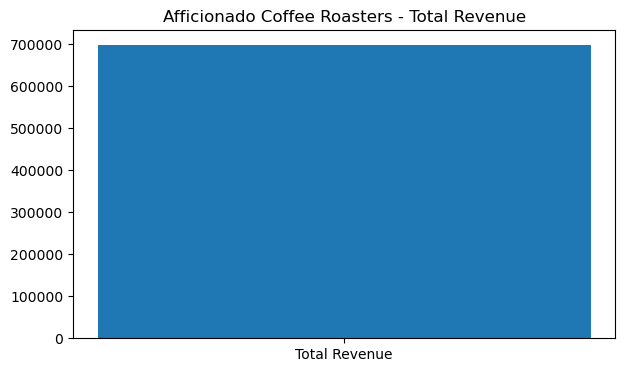

In [28]:
plt.figure(figsize=(7,4))
plt.bar(
    ['Total Revenue'],
    [total_revenue])
plt.title('Afficionado Coffee Roasters - Total Revenue')
plt.show()

In [29]:
product_sales = clean_df.groupby('product_detail')['transaction_qty'].sum()

top_products = product_sales.sort_values(ascending=False).head(10)

top_products

product_detail
Earl Grey Rg                   4708
Dark chocolate Lg              4668
Morning Sunrise Chai Rg        4643
Latte                          4602
Peppermint Rg                  4564
Columbian Medium Roast Rg      4547
Traditional Blend Chai Rg      4512
Latte Rg                       4497
Our Old Time Diner Blend Sm    4484
Serenity Green Tea Rg          4477
Name: transaction_qty, dtype: int64

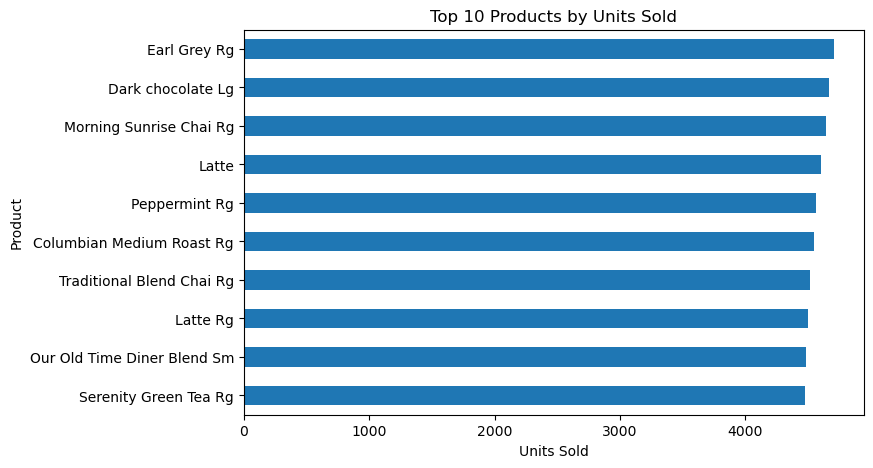

In [30]:
top_products.sort_values().plot(kind='barh', figsize=(8,5))

plt.title('Top 10 Products by Units Sold')
plt.xlabel('Units Sold')
plt.ylabel('Product')
plt.show()

In [31]:
product_revenue = clean_df.groupby('product_detail')['revenue'].sum()

top_revenue_products = product_revenue.sort_values(
    ascending=False
).head(10)

top_revenue_products

product_detail
Sustainably Grown Organic Lg    21151.75
Dark chocolate Lg               21006.00
Latte Rg                        19112.25
Cappuccino Lg                   17641.75
Morning Sunrise Chai Lg         17384.00
Latte                           17257.50
Jamaican Coffee River Lg        16481.25
Sustainably Grown Organic Rg    16233.75
Cappuccino                      15997.50
Brazilian Lg                    15109.50
Name: revenue, dtype: float64

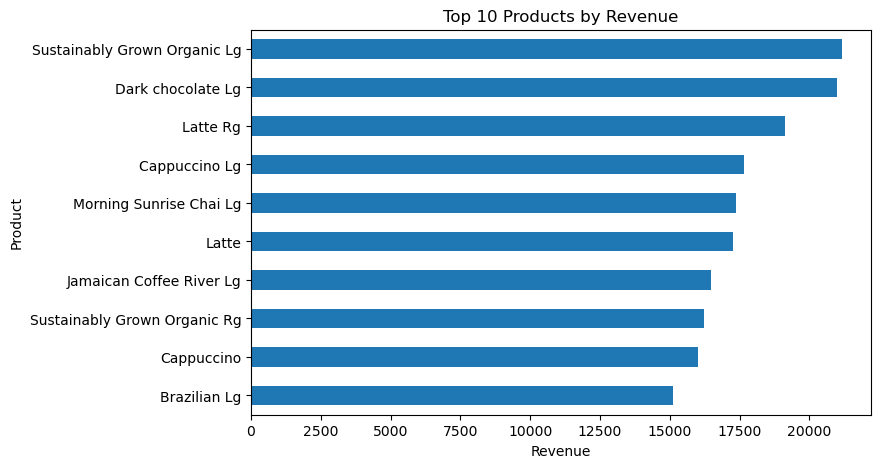

In [32]:
top_revenue_products.sort_values().plot(
    kind='barh',
    figsize=(8,5)
)

plt.title('Top 10 Products by Revenue')
plt.xlabel('Revenue')
plt.ylabel('Product')
plt.show()

In [33]:
product_analysis = clean_df.groupby('product_detail').agg(
    units_sold=('transaction_qty', 'sum'),
    revenue=('revenue', 'sum')
).reset_index()

product_analysis.head()

,product_detail,units_sold,revenue
0,Almond Croissant,1911,7168.13
1,Brazilian - Organic,214,3852.00
2,Brazilian Lg,4317,15109.50
3,Brazilian Rg,4385,13155.00
4,Brazilian Sm,4310,9482.00


In [34]:
product_analysis['revenue_share'] = (
    product_analysis['revenue'] / product_analysis['revenue'].sum() * 100
)

product_analysis.head()

,product_detail,units_sold,revenue,revenue_share
0,Almond Croissant,1911,7168.13,1.025759
1,Brazilian - Organic,214,3852.00,0.551221
2,Brazilian Lg,4317,15109.50,2.162168
3,Brazilian Rg,4385,13155.00,1.882480
4,Brazilian Sm,4310,9482.00,1.356874


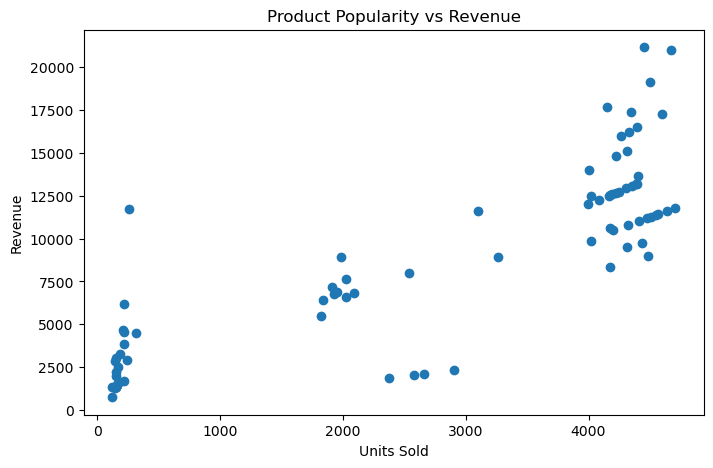

In [35]:
plt.figure(figsize=(8,5))

plt.scatter(
    product_analysis['units_sold'],
    product_analysis['revenue']
)

plt.title('Product Popularity vs Revenue')
plt.xlabel('Units Sold')
plt.ylabel('Revenue')

plt.show()

In [36]:
category_revenue = clean_df.groupby('product_category')['revenue'].sum().sort_values(ascending=False)

category_revenue

product_category
Coffee                269952.45
Tea                   196405.95
Bakery                 82315.64
Drinking Chocolate     72416.00
Coffee beans           40085.25
Branded                13607.00
Loose Tea              11213.60
Flavours                8408.80
Packaged Chocolate      4407.64
Name: revenue, dtype: float64

In [37]:
category_share = (
    category_revenue / category_revenue.sum() * 100
).round(2)

category_share

product_category
Coffee                38.63
Tea                   28.11
Bakery                11.78
Drinking Chocolate    10.36
Coffee beans           5.74
Branded                1.95
Loose Tea              1.60
Flavours               1.20
Packaged Chocolate     0.63
Name: revenue, dtype: float64

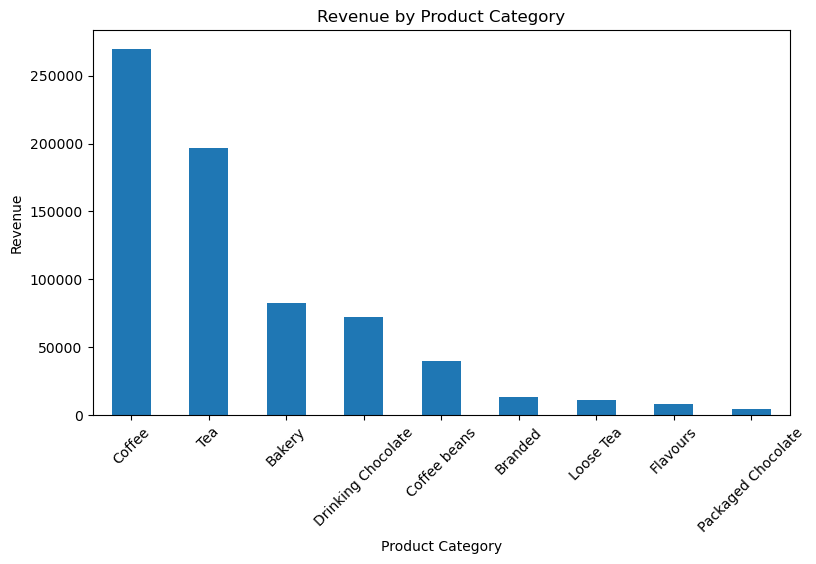

In [38]:
category_revenue.plot(kind='bar', figsize=(9,5))

plt.title('Revenue by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Revenue')
plt.xticks(rotation=45)

plt.show()

In [39]:
type_revenue = clean_df.groupby(
    ['product_category', 'product_type']
)['revenue'].sum().sort_values(ascending=False)

type_revenue.head(15)

product_category    product_type         
Coffee              Barista Espresso         91406.20
Tea                 Brewed Chai tea          77081.95
Drinking Chocolate  Hot chocolate            72416.00
Coffee              Gourmet brewed coffee    70034.60
Tea                 Brewed Black tea         47932.00
                    Brewed herbal tea        47539.50
Coffee              Premium brewed coffee    38781.15
                    Organic brewed coffee    37746.50
Bakery              Scone                    36866.12
Coffee              Drip coffee              31984.00
Bakery              Pastry                   25655.99
Tea                 Brewed Green tea         23852.50
Bakery              Biscotti                 19793.53
Coffee beans        Premium Beans            14583.50
                    Organic Beans             8509.50
Name: revenue, dtype: float64

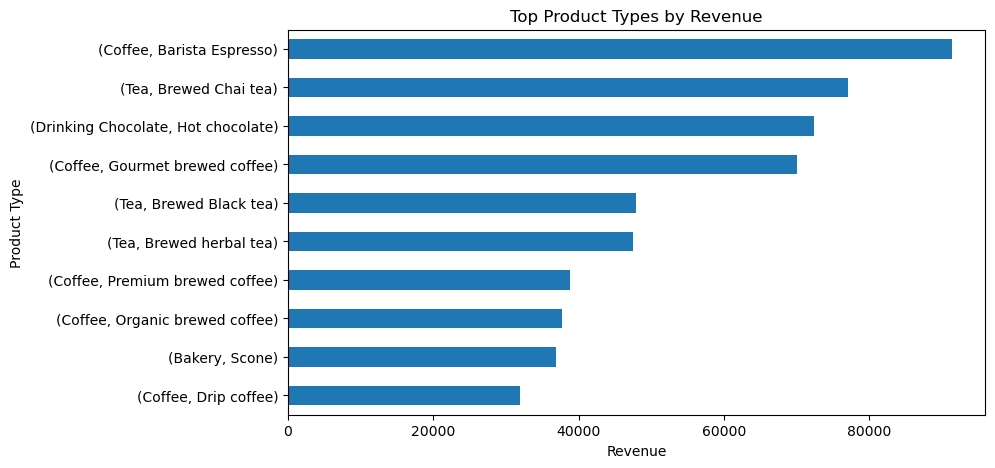

In [40]:
top_types = type_revenue.head(10)

top_types.sort_values().plot(
    kind='barh',
    figsize=(9,5)
)

plt.title('Top Product Types by Revenue')
plt.xlabel('Revenue')
plt.ylabel('Product Type')
plt.show()

In [41]:
category_type_summary = clean_df.groupby(
    ['product_category', 'product_type']
).agg(
    units_sold=('transaction_qty', 'sum'),
    revenue=('revenue', 'sum')
).reset_index()

category_type_summary.sort_values(
    'revenue',
    ascending=False
).head(15)

,product_category,product_type,units_sold,revenue
5,Coffee,Barista Espresso,24943,91406.20
26,Tea,Brewed Chai tea,26250,77081.95
16,Drinking Chocolate,Hot chocolate,17457,72416.00
7,Coffee,Gourmet brewed coffee,25973,70034.60
25,Tea,Brewed Black tea,17462,47932.00
28,Tea,Brewed herbal tea,17328,47539.50
9,Coffee,Premium brewed coffee,12431,38781.15
8,Coffee,Organic brewed coffee,13012,37746.50
2,Bakery,Scone,10465,36866.12
6,Coffee,Drip coffee,12891,31984.00


In [42]:
product_revenue = (
    clean_df.groupby('product_detail')['revenue']
    .sum()
    .sort_values(ascending=False)
)

product_revenue.head(10)

product_detail
Sustainably Grown Organic Lg    21151.75
Dark chocolate Lg               21006.00
Latte Rg                        19112.25
Cappuccino Lg                   17641.75
Morning Sunrise Chai Lg         17384.00
Latte                           17257.50
Jamaican Coffee River Lg        16481.25
Sustainably Grown Organic Rg    16233.75
Cappuccino                      15997.50
Brazilian Lg                    15109.50
Name: revenue, dtype: float64

In [43]:
cumulative_revenue = (
    product_revenue.cumsum() /
    product_revenue.sum() * 100
)

cumulative_revenue.head(10)

product_detail
Sustainably Grown Organic Lg     3.026814
Dark chocolate Lg                6.032771
Latte Rg                         8.767733
Cappuccino Lg                   11.292266
Morning Sunrise Chai Lg         13.779916
Latte                           16.249463
Jamaican Coffee River Lg        18.607929
Sustainably Grown Organic Rg    20.930977
Cappuccino                      23.220219
Brazilian Lg                    25.382387
Name: revenue, dtype: float64

In [44]:
products_for_80 = (cumulative_revenue <= 80).sum()

print("Products contributing up to 80% revenue:", products_for_80)

Products contributing up to 80% revenue: 42


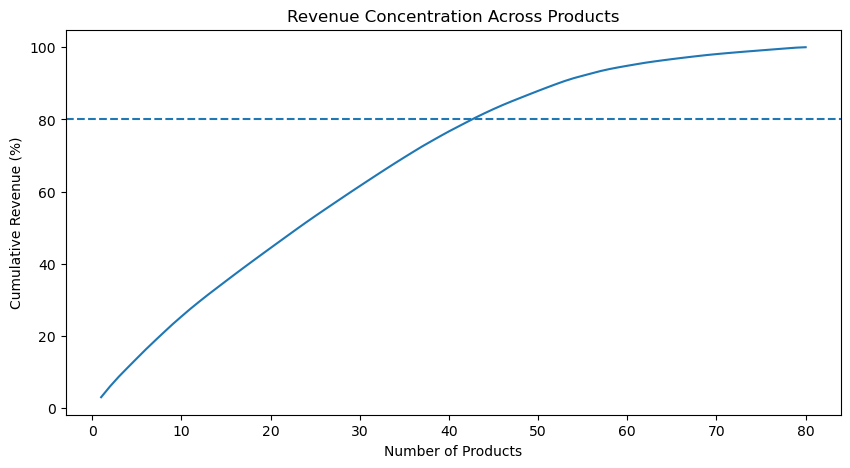

In [45]:
plt.figure(figsize=(10,5))

plt.plot(
    range(1, len(cumulative_revenue) + 1),
    cumulative_revenue
)

plt.axhline(80, linestyle='--')

plt.title('Revenue Concentration Across Products')
plt.xlabel('Number of Products')
plt.ylabel('Cumulative Revenue (%)')

plt.show()

In [46]:
product_performance = clean_df.groupby('product_detail').agg(
    units_sold=('transaction_qty', 'sum'),
    revenue=('revenue', 'sum')
).reset_index()

product_performance['revenue_share'] = (
    product_performance['revenue'] /
    product_performance['revenue'].sum() * 100
)

In [47]:
hero_products = product_performance.sort_values(
    'revenue',
    ascending=False
).head(10)

hero_products

,product_detail,units_sold,revenue,revenue_share
75,Sustainably Grown Organic Lg,4453,21151.75,3.026814
20,Dark chocolate Lg,4668,21006.00,3.005957
48,Latte Rg,4497,19112.25,2.734962
6,Cappuccino Lg,4151,17641.75,2.524533
53,Morning Sunrise Chai Lg,4346,17384.00,2.487649
47,Latte,4602,17257.50,2.469547
43,Jamaican Coffee River Lg,4395,16481.25,2.358466
76,Sustainably Grown Organic Rg,4329,16233.75,2.323049
5,Cappuccino,4266,15997.50,2.289241
2,Brazilian Lg,4317,15109.50,2.162168


In [48]:
low_impact_products = product_performance.sort_values(
    'revenue',
    ascending=True
).head(10)

low_impact_products

,product_detail,units_sold,revenue,revenue_share
19,Dark chocolate,118,755.20,0.108069
22,Earl Grey,142,1270.90,0.181866
70,Spicy Eye Opener Chai,122,1335.90,0.191167
36,Guatemalan Sustainably Grown,134,1340.00,0.191754
49,Lemon Grass,152,1360.40,0.194673
62,Peppermint,153,1369.35,0.195954
77,Traditional Blend Chai,153,1369.35,0.195954
25,English Breakfast,161,1440.95,0.206200
67,Serenity Green Tea,159,1470.75,0.210464
52,Morning Sunrise Chai,168,1596.00,0.228387


In [49]:
product_performance['revenue_per_unit'] = (
    product_performance['revenue'] /
    product_performance['units_sold']
)

product_performance.sort_values(
    'revenue_per_unit',
    ascending=False
).head(10)

,product_detail,units_sold,revenue,revenue_share,revenue_per_unit
12,Civet Cat,260,11700.00,1.674269,45.000000
41,I Need My Bean! T-shirt,221,6163.00,0.881925,27.886878
56,Organic Decaf Blend,206,4657.50,0.666488,22.609223
30,Ethiopia,218,4578.00,0.655112,21.000000
65,Primo Espresso Roast,150,3067.50,0.438959,20.450000
42,Jamacian Coffee River,146,2883.50,0.412629,19.750000
1,Brazilian - Organic,214,3852.00,0.551221,18.000000
57,Our Old Time Diner Blend,183,3294.00,0.471371,18.000000
13,Columbian Medium Roast,148,2220.00,0.317682,15.000000
28,Espresso Roast,169,2492.75,0.356712,14.750000


In [50]:
location_revenue = clean_df.groupby('store_location')['revenue'].sum().sort_values(ascending=False)

location_revenue

store_location
Hell's Kitchen     236511.17
Astoria            232243.91
Lower Manhattan    230057.25
Name: revenue, dtype: float64

In [51]:
location_units = clean_df.groupby('store_location')['transaction_qty'].sum().sort_values(ascending=False)

location_units

store_location
Lower Manhattan    71742
Hell's Kitchen     71737
Astoria            70991
Name: transaction_qty, dtype: int64

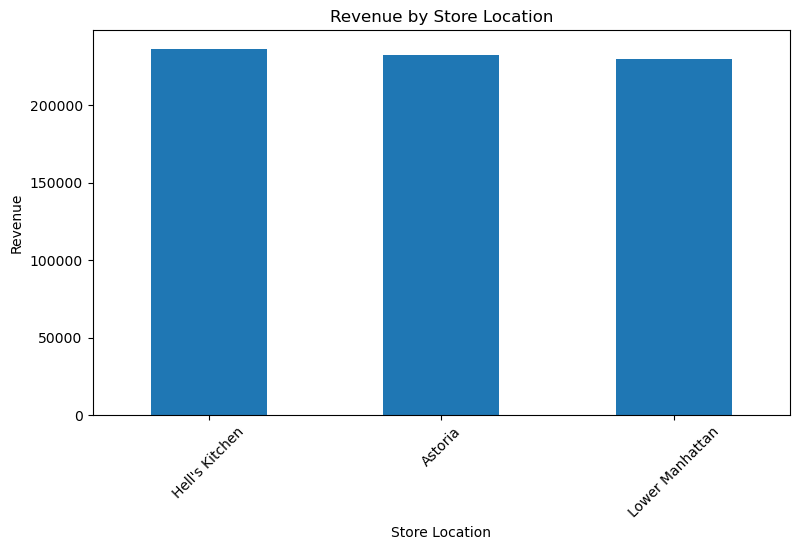

In [52]:
location_revenue.plot(kind='bar', figsize=(9,5))

plt.title('Revenue by Store Location')
plt.xlabel('Store Location')
plt.ylabel('Revenue')
plt.xticks(rotation=45)

plt.show()

In [53]:
location_summary = clean_df.groupby('store_location').agg(
    transactions=('transaction_id', 'nunique'),
    units_sold=('transaction_qty', 'sum'),
    revenue=('revenue', 'sum')
).reset_index()

location_summary

,store_location,transactions,units_sold,revenue
0,Astoria,50599,70991,232243.91
1,Hell's Kitchen,50735,71737,236511.17
2,Lower Manhattan,47782,71742,230057.25


In [54]:
final_product_table = clean_df.groupby(
    ['product_category', 'product_type', 'product_detail']
).agg(
    units_sold=('transaction_qty', 'sum'),
    revenue=('revenue', 'sum'),
    avg_price=('unit_price', 'mean')
).reset_index()

final_product_table['revenue_share'] = (
    final_product_table['revenue'] /
    final_product_table['revenue'].sum() * 100
)

final_product_table = final_product_table.sort_values(
    'revenue',
    ascending=False
)

final_product_table.head(15)

,product_category,product_type,product_detail,units_sold,revenue,avg_price,revenue_share
47,Drinking Chocolate,Hot chocolate,Sustainably Grown Organic Lg,4453,21151.75,4.75,3.026814
45,Drinking Chocolate,Hot chocolate,Dark chocolate Lg,4668,21006.00,4.50,3.005957
18,Coffee,Barista Espresso,Latte Rg,4497,19112.25,4.25,2.734962
15,Coffee,Barista Espresso,Cappuccino Lg,4151,17641.75,4.25,2.524533
68,Tea,Brewed Chai tea,Morning Sunrise Chai Lg,4346,17384.00,4.00,2.487649
17,Coffee,Barista Espresso,Latte,4602,17257.50,3.75,2.469547
32,Coffee,Premium brewed coffee,Jamaican Coffee River Lg,4395,16481.25,3.75,2.358466
48,Drinking Chocolate,Hot chocolate,Sustainably Grown Organic Rg,4329,16233.75,3.75,2.323049
14,Coffee,Barista Espresso,Cappuccino,4266,15997.50,3.75,2.289241
29,Coffee,Organic brewed coffee,Brazilian Lg,4317,15109.50,3.50,2.162168


In [55]:
final_product_table.to_csv(
    'product_performance_analysis.csv',
    index=False
)

In [56]:
print("===== FINAL ANALYSIS SUMMARY =====")
print("Total Revenue: ₹", round(clean_df['revenue'].sum(), 2))
print("Total Units Sold:", clean_df['transaction_qty'].sum())
print("Total Transactions:", clean_df['transaction_id'].nunique())
print("Unique Products:", clean_df['product_id'].nunique())
print("Categories:", clean_df['product_category'].nunique())
print("Locations:", clean_df['store_location'].nunique())

===== FINAL ANALYSIS SUMMARY =====
Total Revenue: ₹ 698812.33
Total Units Sold: 214470
Total Transactions: 149116
Unique Products: 80
Categories: 9
Locations: 3


In [57]:
top_revenue = final_product_table.sort_values(
    'revenue', ascending=False
).head(10)

top_revenue[['product_detail', 'units_sold', 'revenue', 'revenue_share']]

,product_detail,units_sold,revenue,revenue_share
47,Sustainably Grown Organic Lg,4453,21151.75,3.026814
45,Dark chocolate Lg,4668,21006.00,3.005957
18,Latte Rg,4497,19112.25,2.734962
15,Cappuccino Lg,4151,17641.75,2.524533
68,Morning Sunrise Chai Lg,4346,17384.00,2.487649
17,Latte,4602,17257.50,2.469547
32,Jamaican Coffee River Lg,4395,16481.25,2.358466
48,Sustainably Grown Organic Rg,4329,16233.75,2.323049
14,Cappuccino,4266,15997.50,2.289241
29,Brazilian Lg,4317,15109.50,2.162168


In [58]:
top_volume = final_product_table.sort_values(
    'units_sold', ascending=False
).head(10)

top_volume[['product_detail', 'units_sold', 'revenue']]

,product_detail,units_sold,revenue
65,Earl Grey Rg,4708,11770.00
45,Dark chocolate Lg,4668,21006.00
69,Morning Sunrise Chai Rg,4643,11607.50
17,Latte,4602,17257.50
79,Peppermint Rg,4564,11410.00
24,Columbian Medium Roast Rg,4547,11367.50
73,Traditional Blend Chai Rg,4512,11280.00
18,Latte Rg,4497,19112.25
22,Our Old Time Diner Blend Sm,4484,8968.00
75,Serenity Green Tea Rg,4477,11192.50


In [59]:
low_revenue = final_product_table.sort_values(
    'revenue', ascending=True
).head(10)

low_revenue[['product_detail', 'units_sold', 'revenue']]

,product_detail,units_sold,revenue
62,Dark chocolate,118,755.20
53,Earl Grey,142,1270.90
56,Spicy Eye Opener Chai,122,1335.90
39,Guatemalan Sustainably Grown,134,1340.00
59,Lemon Grass,152,1360.40
57,Traditional Blend Chai,153,1369.35
60,Peppermint,153,1369.35
54,English Breakfast,161,1440.95
58,Serenity Green Tea,159,1470.75
55,Morning Sunrise Chai,168,1596.00


In [60]:
category_summary = clean_df.groupby(
    'product_category'
).agg(
    units_sold=('transaction_qty', 'sum'),
    revenue=('revenue', 'sum'),
    products=('product_id', 'nunique')
).reset_index()

category_summary['revenue_share'] = (
    category_summary['revenue'] /
    category_summary['revenue'].sum() * 100
).round(2)

category_summary.sort_values(
    'revenue', ascending=False
)

,product_category,units_sold,revenue,products,revenue_share
2,Coffee,89250,269952.45,21,38.63
8,Tea,69737,196405.95,16,28.11
0,Bakery,23214,82315.64,11,11.78
4,Drinking Chocolate,17457,72416.00,4,10.36
3,Coffee beans,1828,40085.25,10,5.74
1,Branded,776,13607.00,3,1.95
6,Loose Tea,1210,11213.60,8,1.60
5,Flavours,10511,8408.80,4,1.20
7,Packaged Chocolate,487,4407.64,3,0.63


In [61]:
top_10_revenue = final_product_table.sort_values(
    'revenue', ascending=False
).head(10)

top_10_revenue[['product_detail', 'revenue']]

,product_detail,revenue
47,Sustainably Grown Organic Lg,21151.75
45,Dark chocolate Lg,21006.00
18,Latte Rg,19112.25
15,Cappuccino Lg,17641.75
68,Morning Sunrise Chai Lg,17384.00
17,Latte,17257.50
32,Jamaican Coffee River Lg,16481.25
48,Sustainably Grown Organic Rg,16233.75
14,Cappuccino,15997.50
29,Brazilian Lg,15109.50


In [62]:
top_10_units = final_product_table.sort_values(
    'units_sold', ascending=False
).head(10)

top_10_units[['product_detail', 'units_sold']]

,product_detail,units_sold
65,Earl Grey Rg,4708
45,Dark chocolate Lg,4668
69,Morning Sunrise Chai Rg,4643
17,Latte,4602
79,Peppermint Rg,4564
24,Columbian Medium Roast Rg,4547
73,Traditional Blend Chai Rg,4512
18,Latte Rg,4497
22,Our Old Time Diner Blend Sm,4484
75,Serenity Green Tea Rg,4477


In [63]:
category_revenue = clean_df.groupby(
    'product_category'
)['revenue'].sum().sort_values(ascending=False)

category_revenue

product_category
Coffee                269952.45
Tea                   196405.95
Bakery                 82315.64
Drinking Chocolate     72416.00
Coffee beans           40085.25
Branded                13607.00
Loose Tea              11213.60
Flavours                8408.80
Packaged Chocolate      4407.64
Name: revenue, dtype: float64

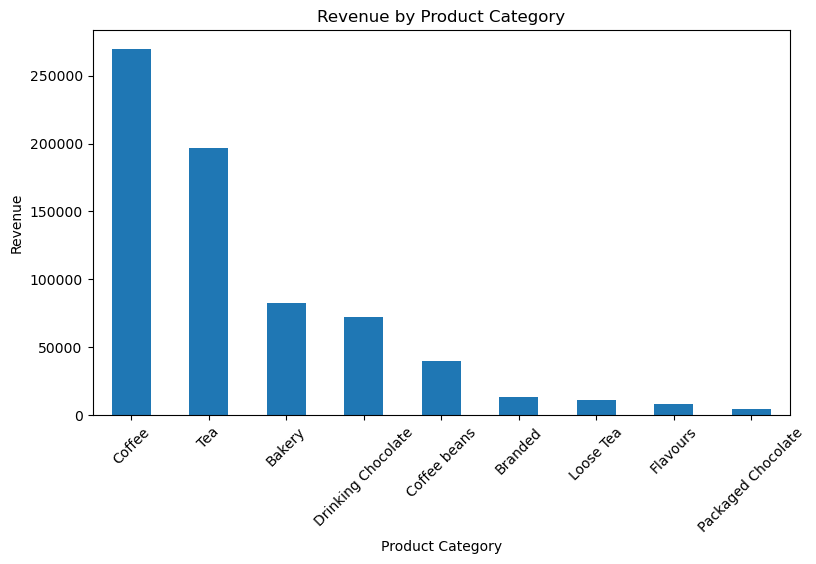

In [64]:
category_revenue.plot(
    kind='bar',
    figsize=(9,5)
)

plt.title('Revenue by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.show()